# setup + imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import json
from sklearn.ensemble import HistGradientBoostingRegressor, HistGradientBoostingClassifier
from sklearn.decomposition import PCA
from sklearn.feature_extraction.text import TfidfVectorizer

In [2]:
from sklearn.cluster import KMeans
from sklearn.decomposition import TruncatedSVD
from sklearn.ensemble import HistGradientBoostingClassifier
import re

In [3]:
from sentence_transformers import SentenceTransformer

/Users/ecaterina/practice/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1029 18:06:13.538000 58251 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


In [4]:
categs = ["dp", "geometry", "graphs", "number theory", "strings"]
data = pd.read_csv('dataset.csv')

# data exploration

In [5]:
data.dtypes

id                   str
title                str
description          str
statement            str
input_format         str
output_format        str
examples             str
time_limit       float64
memory_limit     float64
rating           float64
dtype: object

In [6]:
data.isnull().sum()

id                0
title             0
description       0
statement         0
input_format      0
output_format     0
examples          0
time_limit        0
memory_limit      0
rating           11
dtype: int64

In [7]:
'''
for c in data.columns:
    print(c, ':', str(data[c].iloc[0])[:300], '\n')
'''

"\nfor c in data.columns:\n    print(c, ':', str(data[c].iloc[0])[:300], '\n')\n"

In [8]:
same = 0
starts = 0
for d, s in zip(data['description'].fillna(''), data['statement'].fillna('')):
    if d == s:
        same += 1
    if s.startswith(d[:1000]):
        starts += 1
print('identical:', same, ' statement starts with description:', starts, ' of', len(data))

identical: 598  statement starts with description: 598  of 598


# data preprocessing

In [9]:
goodcols = ['title', 'statement', 'input_format', 'output_format']

text = data['title'].astype(str)
for i in range(1, len(goodcols)):
    c = goodcols[i]
    text = text + ' ' + data[c].astype(str)

'''
newcols = ['time_limit', 'memory_limit']
for i in range(1, len(newcols)):
    c = newcols[i]
    text = text + ' ' + data[c].astype(str)
'''

"\nnewcols = ['time_limit', 'memory_limit']\nfor i in range(1, len(newcols)):\n    c = newcols[i]\n    text = text + ' ' + data[c].astype(str)\n"

# model

In [10]:
vec = TfidfVectorizer(stop_words='english', min_df=3, max_df=0.5)
emb1 = vec.fit_transform(text)

K = len(categs)+2
km = KMeans(n_clusters=K, n_init=50, random_state=0).fit(emb1)
clusters = km.labels_

# validare

In [11]:
print(np.bincount(clusters))
print(pd.Series(clusters).value_counts())

[ 34  94 127  32  81  49 181]
6    181
2    127
1     94
4     81
5     49
0     34
3     32
Name: count, dtype: int64


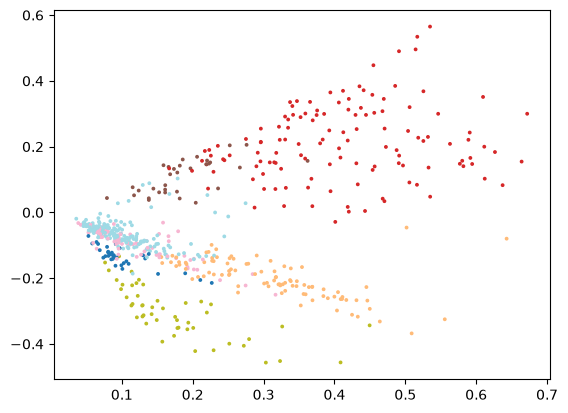

In [12]:
tsvd = TruncatedSVD(n_components=2, random_state=0).fit_transform(emb1)
plt.scatter(tsvd[:, 0], tsvd[:, 1], c=clusters, s=3, cmap='tab20')

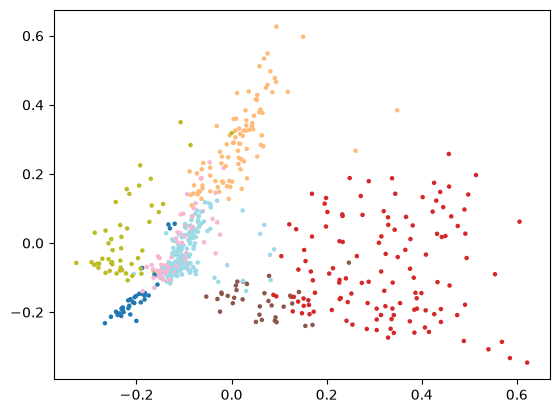

In [13]:
pca = PCA(n_components=2, random_state=0).fit_transform(emb1)
plt.scatter(pca[:, 0], pca[:, 1], c=clusters, s=5, cmap='tab20')

In [14]:
'''
for c in range(K):
    print("cluster " + str(c) + ":\n")
    nr = 0
    for i in range(len(data)):
        if clusters[i] == c:
            s = text[i]
            print(s[:500])
            print("\n")
            nr += 1
        if nr > 8:
            break
            
    print("\n")
'''

'\nfor c in range(K):\n    print("cluster " + str(c) + ":\n")\n    nr = 0\n    for i in range(len(data)):\n        if clusters[i] == c:\n            s = text[i]\n            print(s[:500])\n            print("\n")\n            nr += 1\n        if nr > 8:\n            break\n\n    print("\n")\n'

In [15]:
name = {0: 'graphs', 1: 'number theory', 2: 'strings', 3: 'strings',
        4: 'geometry', 5: 'graphs', 6: 'dp'}

In [16]:
labels = []
for i in range(len(data)):
    label = name[clusters[i]]
    labels.append(label)

pred_tfidf = np.array(labels)

# keywords useful!!

In [17]:
data['label'] = labels

In [18]:
dists = km.transform(emb1)
sdists = np.sort(dists, axis=1)
margin = sdists[:, 1]-sdists[:, 0]
cut = np.quantile(margin, 0.3)

keywords = {
    'graphs': ['graph', 'vertex', 'vertices', 'edge', 'edges', 'tree', 'cities', 'roads', 'connected', 'cycle'],
    'geometry': ['polygon', 'coordinates', 'angle', 'circle', 'triangle', 'area', 'segment', 'plane', 'convex'],
    'strings': ['string', 'strings', 'substring', 'palindrome', 'characters', 'letters', 'prefix', 'suffix', 'lowercase'],
    'number theory': ['prime', 'divisor', 'divisible', 'gcd', 'lcm', 'modulo', 'factorization', 'coprime', 'remainder'],
}

def keyword_scores(t):
    words = re.findall(r'[a-z]+', t.lower())
    return {cat: sum(words.count(k) for k in keywords[cat]) for cat in keywords}

final = []
for i in range(len(data)):
    lab = name[clusters[i]]
    s = keyword_scores(text[i])
    best = max(s, key=s.get)
    if s[best] >= 5 and best != lab and (lab == 'dp' or margin[i] < cut):
        lab = best
    final.append(lab)

pred_amended = np.array(final)

data['label'] = final
print(data['label'].value_counts())

label
strings          170
dp               144
number theory    110
graphs            91
geometry          83
Name: count, dtype: int64


In [19]:
pred_kw = []
for i in range(len(data)):
    s = keyword_scores(text[i])
    best = max(s, key=s.get)
    if s[best] >= 5:
        pred_kw.append(best)
    else:
        pred_kw.append('dp')      # no strong keywords -> dp
pred_kw = np.array(pred_kw)


# sentence transformers

In [20]:
text_st = (data['title'].fillna('') + '. ' + data['input_format'].fillna('') + ' ' +
           data['output_format'].fillna('') + ' ' + data['statement'].fillna(''))


st = SentenceTransformer('all-MiniLM-L6-v2')
E = st.encode(list(text_st), normalize_embeddings=True, show_progress_bar=True)

desc = {
    'dp': 'count the number of ways, minimum cost, maximum sum over subsequences, optimal choice step by step',
    'geometry': 'points, coordinates, polygon, circle, area, angle, distance in the plane',
    'graphs': 'vertices and edges, tree, roads between cities, shortest path, connected components',
    'number theory': 'prime numbers, divisors, gcd, lcm, modulo, remainders, divisibility',
    'strings': 'string of lowercase letters, substring, palindrome, prefix, suffix, characters',
}
C = st.encode(list(desc.values()), normalize_embeddings=True)
cats = np.array(list(desc.keys()))
pred_st = cats[(E @ C.T).argmax(axis=1)]
pd.Series(pred_st).value_counts()

Batches: 100%|█████████████████████████████████| 19/19 [00:03<00:00,  5.70it/s]


dp               248
strings          145
graphs            96
number theory     61
geometry          48
Name: count, dtype: int64

In [21]:
K2 = 8
km2 = KMeans(n_clusters=K2, n_init=50, random_state=0).fit(E)
clusters2 = km2.labels_

words = vec.get_feature_names_out()
for c in range(K2):
    rows = emb1[clusters2 == c]
    mean = np.asarray(rows.mean(axis=0)).ravel()     # average TF-IDF of the cluster
    top = mean.argsort()[::-1][:12]
    print(c, (clusters2 == c).sum(), [words[i] for i in top])

0 67 ['gcd', 'le', 'prime', 'numbers', 'positive', 'leq', 'common', 'lcm', 'array', 'divisible', 'divisor', 'greatest']
1 70 ['string', 'test', 'le', 'strings', 'case', 'cases', 'letters', 'length', 'lowercase', 'leq', '10', 'characters']
2 70 ['point', 'points', 'coordinates', 'triangle', 'polygon', 'area', 'angle', '10', 'le', 'fence', 'sides', 'rectangle']
3 51 ['graph', 'edges', 'vertices', 'vertex', 'edge', 'tree', 'connected', 'nodes', 'friends', 'undirected', 'path', 'le']
4 115 ['le', 'th', 'game', 'square', 'modulo', 'sequence', 'time', 'ai', 'player', 'maximum', 'color', 'table']
5 104 ['string', 'letters', 'word', 'characters', 'lowercase', 'letter', 'length', 'strings', 'latin', 'consisting', 'character', 'english']
6 45 ['roads', 'cities', 'road', 'city', 'junctions', 'berland', 'bi', 'ai', 'capital', 'path', 'connected', 'pair']
7 76 ['test', 'le', 'cases', '10', 'case', 'array', 'leq', 'a_i', 'cdot', 'a_1', 'a_2', 'sum']


In [22]:
name2 = {0: 'number theory', 1: 'strings', 2: 'geometry', 3: 'graphs',
         4: 'dp', 5: 'strings', 6: 'graphs', 7: 'dp'}
pred_st_clu = np.array([name2[c] for c in clusters2])

# voting

In [25]:
d2 = np.sort(km2.transform(E), axis=1)
margin2 = d2[:, 1] - d2[:, 0]

# rank of each problem's margin within its own method, scaled to 0..1
conf1 = margin.argsort().argsort() / len(margin)
conf2 = margin2.argsort().argsort() / len(margin2)

# mixed clusters get no say: the TF-IDF side decides there
conf2[(clusters2 == 4) | (clusters2 == 7)] = 0

combined = []
for i in range(len(data)):
    if pred_amended[i] == pred_st_clu[i] or conf1[i] >= conf2[i]:
        combined.append(pred_amended[i])
    else:
        combined.append(pred_st_clu[i])
combined = np.array(combined)

print('disagree:', np.mean(pred_amended != pred_st_clu))
print(pd.Series(combined).value_counts())
data['label'] = combined
data[['id', 'label']].to_csv('submission.csv', index=False)

disagree: 0.23578595317725753
strings          173
number theory    123
dp               120
graphs            98
geometry          84
Name: count, dtype: int64
